# **Section 1 – PEW Research Dataset (Pew NPORS 2023–2025)**

This section uses three annual Pew Research Center **National Public Opinion Reference Surveys (NPORS)**, 2023–2025, with **16,381 respondents** in total, distributed by the Association of Religion Data Archives (ARDA). Instead of the handout's small religion-and-income table, it applies the same tidy-data ideas to real survey data: validating coded answers, harmonizing three yearly releases, reshaping with `melt()`, and testing a hypothesis.

The raw answer codes are stored in the shared **Neon** (cloud PostgreSQL) database and loaded from there. Reusable helpers live in [`src/pew_dataset/`](../src/pew_dataset/). The Neon connection class `NeonDatabase` lives in [`src/common/database.py`](../src/common/database.py) and is shared with the other sections.

## **The Research Question**

> **Do adults who use the internet "almost constantly" differ in average age from internet users who go online less often?**

Why this question?

- **Internet-use intensity** is one of the questions asked in every NPORS year, so it can be prepared consistently across all three releases.
- **Age** is the demographic most often linked to technology habits, so a clear age gap would be expected. The question is whether the data confirm it, and how large the gap is.
- **Numeric age is released only for 2023–2024** (2025 gives age groups only), so the formal test uses the 2024 survey.

Every part of the notebook feeds this question: **preparation** validates the coded answers and keeps refusals (code 99) separate from real answers; **missing-value handling** shows what imputation would do to age without letting imputed ages into the test; **reshaping and visualization** explore the shared questions; and **inferential statistics** (Q-Q plots, Shapiro–Wilk, Welch's t-test) answers the question formally.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer

# Locate the project root whether Jupyter was started in the project folder or in notebooks/,
# then put src/ on Python's search path so our own packages can be imported.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from common.database import NeonDatabase  # shared Neon helper (all sections)
from pew_dataset import validate_npors, labels_from_frame
from pew_dataset.config import (
    SURVEY_YEARS, RESULTS_DIR, LABELS_TABLE_NAME, raw_table_name, source_url, codebook_url,
)

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", None)

### **Getting the Pew NPORS 2023–2025 Data**

For this lab we use three annual Pew Research Center NPORS datasets distributed by the Association of Religion Data Archives (ARDA).

**About the Data**

Sources and Download Setup
- 2023 ARDA record and codebook
- 2024 ARDA record and codebook
- 2025 ARDA record and codebook
- Pew NPORS methodology and questionnaires

The data were downloaded from the Association of Religion Data Archives and collected by Pew Research Center. ARDA adds analysis recodes; we use the original named survey fields rather than ARDA's I- recodes. We must acknowledge both ARDA and Pew. Download requires acceptance of the archive's agreement.

**Where the data lives: Neon only**

Because the ARDA files are licensed downloads, they are **not stored in this repository**. The survey data lives in the shared **Neon** database, and this notebook reads it from there:

| Neon table | Contents |
|---|---|
| `npors23_raw`, `npors24_raw`, `npors25_raw` | One row per respondent, answers stored as **raw numeric codes**, so a refusal coded 99 stays distinguishable from a real answer |
| `npors_value_labels` | The SPSS value labels for every coded variable (survey year, variable, code, label) |

- **To run this notebook** you only need the Neon connection string in `.env` (see the README).
- **To (re)load the data into Neon**, whoever holds the ARDA downloads saves them as `data/NPORS23.sav`, `data/NPORS24.sav` and `data/NPORS25.sav` (these names are git-ignored) and runs `PYTHONPATH=src python -m pew_dataset.upload` from the project root. The script verifies that the Neon copy matches the files exactly.

## 1. Data Preparation Pipeline

### **Task 1.1 – Load and Inspect the NPORS Datasets**


1. Preserve raw files and inspect each year before combining. 
2. Display shape, columns, data types, sample rows, missingness and unique IDs. 
3. Numeric codes must be interpreted using their value labels. isna() alone does not identify refusals coded 99.


In [2]:
connection_string = NeonDatabase.read_connection_string()
if not connection_string:
    raise RuntimeError(
        "NEON_DATABASE_URL is not set in .env. The NPORS survey data is stored only in Neon: "
        "add the connection string to .env (see the README)."
    )

db = NeonDatabase(connection_string)
print("Connected to:", db.test_connection()[:60], "...")

# Read each year's raw answer codes (in the original row order) plus the SPSS value labels
raw = {year: db.read_ordered(raw_table_name(year)) for year in SURVEY_YEARS}
value_labels = labels_from_frame(db.read_table(LABELS_TABLE_NAME))
db.close()

source_records = []
for year, frame in raw.items():
    validate_npors(frame, year)
    source_records.append({'survey_year': year, 'neon_table': raw_table_name(year),
        'rows': len(frame), 'columns': len(frame.columns),
        'memory_MB': frame.memory_usage(deep=True).sum()/1e6,
        'source_url': source_url(year), 'codebook_url': codebook_url(year)})
source_report = pd.DataFrame(source_records)
display(source_report)
print('Total respondents:', source_report['rows'].sum())
for year, frame in raw.items():
    print(year, frame.columns.tolist())
source_report.to_csv(RESULTS_DIR / 'source_manifest.csv', index=False)

Connected to: PostgreSQL 18.6 (653b019) on aarch64-unknown-linux-gnu, comp ...


,survey_year,neon_table,rows,columns,memory_MB,source_url,codebook_url
0,2023,npors23_raw,5733,66,3.844017,https://www.thearda.com/data-archive?fid=NPORS23,https://www.thearda.com/data-archive?fid=NPORS...
1,2024,npors24_raw,5626,63,2.835636,https://www.thearda.com/data-archive?fid=NPORS24,https://www.thearda.com/data-archive?fid=NPORS...
2,2025,npors25_raw,5022,46,2.346196,https://www.thearda.com/data-archive?fid=NPORS25,https://www.thearda.com/data-archive?fid=NPORS...


Total respondents: 16381
2023 ['RESPID', 'MODE_2WAY', 'DATERECEIVED', 'INTERVIEW_START', 'INTERVIEW_END', 'DEVICE_TYPE', 'STRATUM', 'LANG_PREF', 'ECON1MOD', 'ECON1BMOD', 'COMTYPE2', 'TYPOLOGYB', 'CRIMESAFE', 'POLICE_FUND', 'MOREGUNIMPACT', 'GUNSTRICT', 'VET1', 'VOL12_CPS', 'EMINUSE', 'INTMOB', 'INTFREQ', 'INTFREQ_COLLAPSED', 'RADIO', 'BOOKS1', 'BOOKS1_REFUSED', 'DEVICE1A', 'SMART2', 'NHISLL', 'RELIGCAT1', 'REGISTRATION', 'PARTY', 'PARTYLN', 'PARTYSUM', 'HISP', 'RACEMOD_1', 'RACEMOD_2', 'RACEMOD_3', 'RACEMOD_4', 'RACEMOD_5', 'RACEMOD_6', 'RACEMOD_99', 'RACEMOD_MIXEDOE', 'RACECMB', 'RACETHN', 'AGE', 'AGECAT', 'AGE_REFUSED', 'BIRTHPLACE', 'GENDER', 'MARITAL', 'EDUCATION', 'EDUCCAT', 'ADULTS', 'VOTED2020', 'VOTEGEN_POST', 'INC_SDT1', 'CREGION', 'DIVISION', 'METRO', 'BASEWT', 'WEIGHT', 'I_GENDER', 'I_RACE', 'I_PARTYID', 'I_EDUC', 'I_RELIGION']
2024 ['RESPID', 'MODE', 'LANGUAGE', 'LANGUAGEINITIAL', 'LANG_PREF', 'SURVEYSTARTDATE', 'SURVEYENDDATE', 'BWAVE', 'BIDENT1_GEOSTRATA', 'ECON1MOD', 'EC

In [3]:
profile = []
for year, frame in raw.items():
    for col in frame.columns:
        profile.append({'year': year, 'column': col, 'dtype': str(frame[col].dtype),
            'system_missing_n': int(frame[col].isna().sum()),
            'system_missing_pct': 100*frame[col].isna().mean(),
            'unique_values': frame[col].nunique(dropna=True)})
quality_raw = pd.DataFrame(profile)
display(quality_raw.groupby('year').agg(columns=('column','count'), total_system_missing=('system_missing_n','sum')))
display(quality_raw.sort_values('system_missing_pct', ascending=False).head(12))
for year in raw:
    print(year, 'INTFREQ codes:', raw[year]['INTFREQ'].value_counts(dropna=False).sort_index().to_dict())
    print(year, 'income labels:', value_labels[year].get('INC_SDT1', {}))
    print(year, 'AGE labels:', value_labels[year].get('AGE', {}))


,columns,total_system_missing
year,,
2023,66,15105
2024,63,17695
2025,46,6924


,year,column,dtype,system_missing_n,system_missing_pct,unique_values
24,2023,BOOKS1_REFUSED,float64,5589,97.488226,1
128,2024,I_PARTYID,float64,3870,68.787771,2
31,2023,PARTYLN,float64,3758,65.550323,3
154,2025,PARTYLN,float64,3175,63.221824,3
96,2024,PARTYLN,float64,3518,62.531106,3
5,2023,DEVICE_TYPE,float64,3516,61.329147,4
70,2024,LANG_PREF,float64,3091,54.941344,2
71,2024,SURVEYSTARTDATE,float64,2751,48.897974,88
69,2024,LANGUAGEINITIAL,float64,2699,47.973694,2
132,2025,LANGUAGEINITIAL,float64,2254,44.882517,2


2023 INTFREQ codes: {1.0: 2122, 2.0: 2614, 3.0: 351, 4.0: 183, 5.0: 140, 99.0: 51, nan: 272}
2023 income labels: {1.0: 'Less than $30,000', 2.0: '$30,000 to less than $40,000', 3.0: '$40,000 to less than $50,000', 4.0: '$50,000 to less than $60,000', 5.0: '$60,000 to less than $70,000', 6.0: '$70,000 to less than $80,000', 7.0: '$80,000 to less than $90,000', 8.0: '$90,000 to less than $100,000', 9.0: '$100,000 or more', 99.0: 'Refused'}
2023 AGE labels: {18.0: '18', 19.0: '19', 20.0: '20', 21.0: '21', 22.0: '22', 23.0: '23', 24.0: '24', 25.0: '25', 26.0: '26', 27.0: '27', 28.0: '28', 29.0: '29', 30.0: '30', 31.0: '31', 32.0: '32', 33.0: '33', 34.0: '34', 35.0: '35', 36.0: '36', 37.0: '37', 38.0: '38', 39.0: '39', 40.0: '40', 41.0: '41', 42.0: '42', 43.0: '43', 44.0: '44', 45.0: '45', 46.0: '46', 47.0: '47', 48.0: '48', 49.0: '49', 50.0: '50', 51.0: '51', 52.0: '52', 53.0: '53', 54.0: '54', 55.0: '55', 56.0: '56', 57.0: '57', 58.0: '58', 59.0: '59', 60.0: '60', 61.0: '61', 62.0: '62', 

### **Task 1.2 – Explain the Problem**

In a Markdown cell below, answer:

- What is not tidy about the original PEW dataset?
- Which values are stored in column names?
- Which column should be treated as the identifier (`id_vars`)?

**For the larger NPORS datasets used here**

| Question | Explanation |
|---|---|
| **What is not tidy?** | The original respondent table is not inherently untidy. One row per person and one column per variable is appropriate. We reshape selected question columns because a long table makes question-response analysis easier. |
| **Which values are stored in column names?** | The selected columns identify questions, such as `RADIO`, `NHISLL` and `VOL12_CPS`. After melting, these names become values in `question_code`. |
| **What is one observation before melting?** | One respondent’s record in one survey year. |
| **What is one observation after melting?** | One respondent’s response to one selected question. |
| **Which columns belong in `id_vars`?** | In our code, `respondent_key` and `survey_year`. These identify whose response it is and which survey it came from. |

**Example: wide format before melting**

| respondent_key | survey_year | RADIO | NHISLL |
|---|---:|---:|---:|
| 2023:123 | 2023 | 1 | 2 |

**Long format after melting**

| respondent_key | survey_year | question_code | raw_response |
|---|---:|---|---:|
| 2023:123 | 2023 | RADIO | 1 |
| 2023:123 | 2023 | NHISLL | 2 |

**Why not deduplicate people with identical demographics?**

Two people can have the same age group, income, education and community type while remaining different respondents. Removing one would discard a genuine observation and change counts and proportions. Duplicate checks should investigate repeated respondent keys or confirmed repeated records—not merely matching demographics.

### **Task 1.3 – Clean, Harmonize & Engineer Features**


Common age categories are 18–29, 30–49, 50–64 and 65+. Education uses the released three-category EDUCCAT in all years. Income boundaries differ: 2023–24 have nine bands while 2025 has eight. We collapse them to six shared bands. Income describes the previous calendar year, so this is a nominal comparison, without inflation adjustment.

2025 INTFREQ already includes code 6 for nonusers. For 2023–24, code 6 is derived only if BOTH EMINUSE and INTMOB explicitly equal no. A refusal is not a no. The common internet-user analysis includes observed frequency codes 1–5 in every year.

Numeric age is available only in 2023–24. Where the released age-category/refusal flag indicates refusal, we mask the numeric refusal code rather than treating it as an observed response. We are not assigning age-band midpoints to 2025. The downloaded 2023–24 AGE metadata explicitly labels 99 as Refused and 98 as 98+. These codes must be handled using that field-specific metadata, not as exact ages. Numeric 98 is retained as the released top-coded value, so age summaries and tests are approximate.

The public-release contract is validated against observed codes; an unexpected code stops the notebook rather than silently becoming missing. An “unexpected code” is a value that the cleaning function does not recognize from the survey’s documented answer codes.

In [4]:
AGE_LABELS = {1:'18–29', 2:'30–49', 3:'50–64', 4:'65+'}
EDU_LABELS = {1:'College graduate+', 2:'Some college', 3:'High school or less'}
COMM_LABELS = {1:'Urban', 2:'Suburban', 3:'Rural'}
FREQ_LABELS = {1:'Almost constantly', 2:'Several times daily', 3:'Once daily',
               4:'Several times weekly', 5:'Less often', 6:'Does not use internet'}
INCOME_OLD = {1:'<30k', 2:'30–40k', 3:'40–50k', 4:'50–70k', 5:'50–70k',
              6:'70–100k', 7:'70–100k', 8:'70–100k', 9:'100k+'}
INCOME_2025 = {1:'<30k', 2:'30–40k', 3:'40–50k', 4:'50–70k', 5:'70–100k',
               6:'100k+', 7:'100k+', 8:'100k+'}
YES_NO = {1:'Yes', 2:'No'}

def checked_map(series, values, field, missing_codes=(99,)):
    unexpected = set(series.dropna().unique()) - set(values) - set(missing_codes)
    if unexpected:
        raise ValueError(f'Unexpected codes in {field}: {unexpected}; inspect codebook.')
    return series.map(values).astype(object).where(lambda s: s.notna(), np.nan)

def harmonize(frame, year):
    out = pd.DataFrame(index=frame.index)
    out['respondent_key'] = str(year) + ':' + frame['RESPID'].astype('int64').astype(str)
    out['survey_year'] = year
    out['age_group'] = checked_map(frame['AGECAT'], AGE_LABELS, 'AGECAT')
    out['education'] = checked_map(frame['EDUCCAT'], EDU_LABELS, 'EDUCCAT')
    out['income_group'] = checked_map(frame['INC_SDT1'], INCOME_2025 if year==2025 else INCOME_OLD, 'INC_SDT1')
    out['community'] = checked_map(frame['COMTYPE2'], COMM_LABELS, 'COMTYPE2')
    out['weight'] = pd.to_numeric(frame['WEIGHT'], errors='raise')
    assert out['weight'].notna().all() and out['weight'].gt(0).all()
    out['age'] = np.nan
    out['age_status'] = 'Not released in 2025'
    if 'AGE' in frame:
        age = pd.to_numeric(frame['AGE'], errors='raise')
        refused = frame['AGECAT'].eq(99)
        if 'AGE_REFUSED' in frame: refused = refused | frame['AGE_REFUSED'].eq(1)
        valid = age.between(18,98) & ~refused
        out['age'] = age.where(valid)
        assert not age.eq(99).where(~refused,False).any(), 'Check AGE refusal handling.'
        out['age_status'] = np.where(refused, 'Refused', np.where(valid & age.eq(98), 'Top-coded 98+', np.where(valid, 'Observed release age', 'Missing/invalid')))
    freq = frame['INTFREQ'].copy()
    if year < 2025:
        nonuser = frame['EMINUSE'].eq(2) & frame['INTMOB'].eq(2)
        # Do not overwrite a valid frequency answer if the record is inconsistent.
        assert not (nonuser & freq.isin([1,2,3,4,5])).any()
        freq = freq.mask(nonuser & (freq.isna() | freq.eq(99)), 6)
    out['frequency_code'] = freq.where(freq.isin(FREQ_LABELS))
    out['internet_frequency'] = checked_map(freq, FREQ_LABELS, 'INTFREQ')
    out['frequency_status'] = np.where(freq.eq(99),'Refused/unknown', np.where(freq.isna(),'Unavailable/skip','Observed or explicit nonuser'))
    out['is_internet_user'] = out['frequency_code'].isin([1,2,3,4,5])
    out['almost_constant'] = np.where(out['is_internet_user'], out['frequency_code'].eq(1).astype(float), np.nan)
    for field in ['RADIO','NHISLL','VOL12_CPS']:
        out[field.lower()] = checked_map(frame[field], YES_NO, field)
    assert out['respondent_key'].is_unique
    return out

clean_by_year = {year: harmonize(frame,year) for year,frame in raw.items()}
combined = pd.concat(clean_by_year.values(), ignore_index=True)
assert len(combined) == sum(map(len, raw.values())) == 16381
assert combined['respondent_key'].is_unique
display(combined.groupby('survey_year').agg(respondents=('respondent_key','size'), numeric_age=('age','count'), internet_users=('is_internet_user','sum')))
display(pd.crosstab(combined['survey_year'], combined['frequency_status']))


,respondents,numeric_age,internet_users
survey_year,,,
2023,5733,5640,5410
2024,5626,5513,5378
2025,5022,0,4812


frequency_status,Observed or explicit nonuser,Refused/unknown,Unavailable/skip
survey_year,,,
2023,5654,51,28
2024,5566,46,14
2025,4975,47,0


**Feature-engineering decisions**
- respondent_key: survey year plus source respondent ID, preventing collisions across years.
- income_group: six common income bands; avoid treating raw category codes as dollar amounts.
- age_group, education, community: labelled categorical features for grouping.
- frequency_code and internet_frequency: ordered frequency coding plus readable labels; category spacing is not a numeric time measure.
- is_internet_user: valid frequency categories 1–5.
- almost_constant: binary analysis indicator among those observed internet users, not a prediction target. Unknown answers and nonusers are not assigned zero.
- age_status and frequency_status: distinguish unavailable, refused, top-coded and usable values.

The 2025 numeric age absence is a release restriction, not ordinary item missingness. Age-based inference uses 2024 only. Year comparisons are descriptive repeated cross sections.

**Explanation**

**1. Shared income bands**  
The surveys use different income brackets: 2023–24 have nine categories, while 2025 has eight. We combine compatible categories into six common bands: **below $30,000; $30,000–under $40,000; $40,000–under $50,000; $50,000–under $70,000; $70,000–under $100,000; and $100,000 or more**. This makes comparisons consistent across years. These are nominal amounts, without inflation adjustment.

**2. Source-qualified respondent ID**  
The `respondent_key` combines the survey year and original respondent ID—for example, `2023:123`. This prevents respondent `123` in one year from being confused with respondent `123` in another year. It does not establish that people are linked across surveys.

**3. Why exact age is unavailable for 2025**  
The downloaded 2025 public-use file provides age groups rather than individual numeric ages. Exact age therefore cannot be recovered from this file. We leave it unavailable rather than inventing ages from group midpoints.

**4. Why retain 98+ without treating it as exact age?**  
The value means **98 years or older**, so it is a valid response rather than missing data. However, the person could be older than 98. The notebook retains the released value and flags it as top-coded; calculations using 98 are therefore approximations.

**5. Why interpret 99 separately for each field?**  
Survey numbers can represent either measurements or answer codes. In these files’ `AGE` field, **99 means “Refused,” not 99 years old**. Other fields may assign different meanings to the same number. We must check each field’s codebook instead of applying one replacement rule everywhere.

**6. Why use concat instead of merge?**  
`pd.concat()` stacks the cleaned yearly datasets as additional rows because they contain separate respondent samples. `merge()` matches related information using shared keys—for example, attaching question descriptions to response records. Matching respondent IDs across years would risk incorrectly linking different people.

####  **Missing Values and Imputation**

Using 2023–24 for numeric-age preparation because 2025 releases only age groups. The name preparation_subset means this two-year numerical preparation subset, not training data.

We identify how much data is missing, compare dropping rows or columns with mean, median and mode filling, and use SimpleImputer to automate replacement.

The goal is to understand how each choice affects sample size and the data’s distribution, then justify an appropriate approach. Imputed examples remain separate so later statistical tests use observed ages only.



,missing_n,missing_fraction
age,206.0,0.018135
age_group,206.0,0.018135
education,116.0,0.010212
income_group,557.0,0.049036
community,157.0,0.013822


Observed ages: 11153


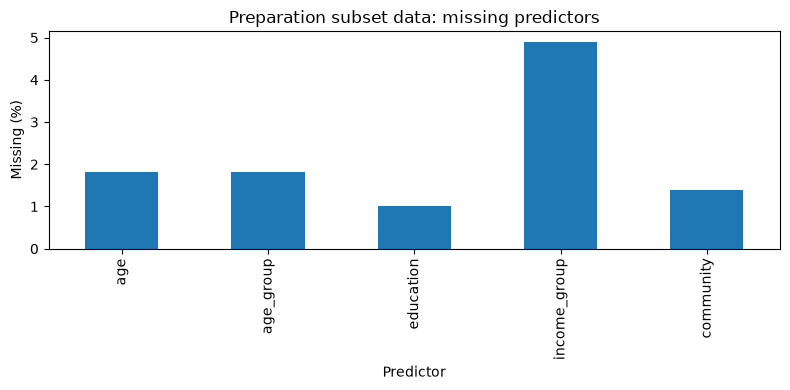

In [5]:
preparation_subset = combined.loc[combined['survey_year'].lt(2025)].copy()
features = ['age','age_group','education','income_group','community']
missing_report = preparation_subset[features].isna().agg(['sum','mean']).T.rename(columns={'sum':'missing_n','mean':'missing_fraction'})
display(missing_report)
print('Observed ages:', preparation_subset['age'].notna().sum())
ax = (missing_report['missing_fraction']*100).plot.bar(figsize=(8,4))
ax.set(title='Preparation subset data: missing predictors', xlabel='Predictor', ylabel='Missing (%)')
plt.tight_layout(); plt.show()


In [6]:
imputation_comparison = []
age_original = preparation_subset['age'].copy()
for name, series in {
    'Observed only': age_original.dropna(),
    'Mean fill': age_original.fillna(age_original.mean()),
    'Median fill': age_original.fillna(age_original.median()),
    'Mode fill (demonstration)': age_original.fillna(age_original.mode().iloc[0])
}.items():
    imputation_comparison.append({'strategy':name, 'n':series.size, 'missing':series.isna().sum(),
        'mean':series.mean(), 'median':series.median(), 'SD':series.std(ddof=1)})
display(pd.DataFrame(imputation_comparison))
print('Original predictor rows:', len(preparation_subset))
print('Rows after any-predictor dropna:', len(preparation_subset[features].dropna()))
print('Columns after dropna(axis=1):', preparation_subset[features].dropna(axis=1).columns.tolist())
age_imputer = SimpleImputer(strategy='median')
age_imputed = age_imputer.fit_transform(preparation_subset[['age']]).ravel()
community_mode = preparation_subset['community'].mode().iloc[0]
community_manual = preparation_subset['community'].fillna(community_mode)
community_imputed = SimpleImputer(strategy='most_frequent').fit_transform(preparation_subset[['community']]).ravel()
assert np.array_equal(community_manual.to_numpy(), community_imputed)
assert np.isfinite(age_imputed).all()
print('SimpleImputer learned median:', age_imputer.statistics_[0])


,strategy,n,missing,mean,median,SD
0,Observed only,11153,0,54.933829,57.0,17.677886
1,Mean fill,11359,0,54.933829,56.0,17.516840
2,Median fill,11359,0,54.971300,57.0,17.519010
3,Mode fill (demonstration),11359,0,55.170790,57.0,17.603408


Original predictor rows: 11359
Rows after any-predictor dropna: 10515
Columns after dropna(axis=1): []
SimpleImputer learned median: 57.0


#### **Outlier Flags and Decision Log**

- Apply |Z|>3 and 1.5×IQR fences to released numeric ages. 
- Use ddof=0 for Z-score SD. 
- Plausible older ages and the top-coded 98+ category are not automatically errors; investigate plots later in EDA. 
- Retain plausible ages and record the reasoning.

In [7]:
outlier_rows=[]
for year,group in preparation_subset.groupby('survey_year'):
    x=group['age'].dropna(); sd=x.std(ddof=0)
    z=(x-x.mean())/sd if sd>0 else pd.Series(0.,index=x.index)
    q1,q3=x.quantile([.25,.75]); iqr=q3-q1
    z_flag=z.abs().gt(3); iqr_flag=x.lt(q1-1.5*iqr)|x.gt(q3+1.5*iqr)
    outlier_rows.append({'year':year,'observed_n':len(x),'Z_abs_gt_3':int(z_flag.sum()),
        'IQR_and_boxplot_rule':int(iqr_flag.sum()),'overlap':int((z_flag&iqr_flag).sum()),
        'IQR_low':q1-1.5*iqr,'IQR_high':q3+1.5*iqr})
outlier_report=pd.DataFrame(outlier_rows); display(outlier_report)
print('Decision: retain plausible observed ages; no statistical outlier deletions.')


,year,observed_n,Z_abs_gt_3,IQR_and_boxplot_rule,overlap,IQR_low,IQR_high
0,2023,5640,0,0,0,-2.0,110.0
1,2024,5513,0,0,0,-3.5,112.5


Decision: retain plausible observed ages; no statistical outlier deletions.


In [8]:
decision_log=pd.DataFrame([
    {'step':'Source harmonization','decision':'Validate codes and align shared categories','reason':'Public releases differ by year'},
    {'step':'Missing codes','decision':'Recode per field, not with a global 99 rule','reason':'99 is refusal in AGE here; other fields require their own metadata'},
    {'step':'Numeric age','decision':'Mask refusal; flag top-coded 98+; leave 2025 unavailable','reason':'Do not invent observed ages'},
    {'step':'Imputation','decision':'Use separate demonstration copies','reason':'Inferential age tests require observed values'},
    {'step':'Outliers','decision':'Retain plausible observed age values','reason':'Statistical extremes can be valid'},
    {'step':'Analysis universe','decision':'Observed internet-user frequency answers','reason':'Do not equate unknown/nonuser with another frequency'}])
display(decision_log)
decision_log.to_csv(RESULTS_DIR/'preprocessing_decisions.csv',index=False)


,step,decision,reason
0,Source harmonization,Validate codes and align shared categories,Public releases differ by year
1,Missing codes,"Recode per field, not with a global 99 rule",99 is refusal in AGE here; other fields requir...
2,Numeric age,Mask refusal; flag top-coded 98+; leave 2025 u...,Do not invent observed ages
3,Imputation,Use separate demonstration copies,Inferential age tests require observed values
4,Outliers,Retain plausible observed age values,Statistical extremes can be valid
5,Analysis universe,Observed internet-user frequency answers,Do not equate unknown/nonuser with another fre...


#### **Reshape NPORS with melt()**

Here we reshape using 3 NPORS datasets.

1. We select six shared questions from all three survey years.
2. Uses melt() to change one row per respondent into one row per respondent–question response.
3. Converts answer codes into readable labels and identifies missing responses.
4. Attaches question descriptions and demographic information using validated merges.
5. Checks that no responses were lost or accidentally duplicated.

The result contains 98,286 response rows from 16,381 respondents. The extra rows represent separate questions—not additional people.

In [9]:
QUESTION_DEFINITIONS={
    'RADIO':('Listens to radio',{1:'Yes',2:'No'}),
    'NHISLL':('Working home landline',{1:'Yes',2:'No'}),
    'VOL12_CPS':('Volunteered in past 12 months',{1:'Yes',2:'No'}),
    'COMTYPE2':('Community type',COMM_LABELS),
    'ECON1MOD':('Current community economic conditions',{1:'Excellent',2:'Good',3:'Only fair',4:'Poor'}),
    'CRIMESAFE':('Neighborhood safety',{1:'Extremely safe',2:'Very safe',3:'Somewhat safe',4:'Not too safe',5:'Not at all safe'})
}
response_parts=[]; question_rows=[]; started=time.perf_counter()
for year in [2023,2024,2025]:
    frame=raw[year]
    wide=frame[list(QUESTION_DEFINITIONS)].copy()
    wide['respondent_key']=str(year)+':'+frame['RESPID'].astype('int64').astype(str)
    wide['survey_year']=year
    long=wide.melt(id_vars=['respondent_key','survey_year'],var_name='question_code',value_name='raw_response')
    assert len(long)==len(frame)*len(QUESTION_DEFINITIONS)
    long['question_code']=long['question_code'].str.strip().str.upper()
    long['question_display']=long['question_code'].str.lower().str.replace('_',' ',regex=False)
    # Missing response codes stay explicit; no missing question is converted to a no.
    long['response_status']=np.where(long['raw_response'].isna(),'System missing/skip',np.where(long['raw_response'].eq(99),'Refused/unknown','Observed'))
    long['response_label']=np.nan
    long['response_label']=long['response_label'].astype(object)
    for question,(description,labels) in QUESTION_DEFINITIONS.items():
        mask=long['question_code'].eq(question)
        long.loc[mask,'response_label']=checked_map(long.loc[mask,'raw_response'],labels,question)
        question_rows.append({'survey_year':year,'question_code':question,'description':description,
            'source_url':f'https://www.thearda.com/data-archive?fid=NPORS{str(year)[-2:]}&tab=2'})
    response_parts.append(long)
responses_long=pd.concat(response_parts,ignore_index=True)
questions=pd.DataFrame(question_rows)
assert not questions.duplicated(['survey_year','question_code']).any()
assert not responses_long.duplicated(['respondent_key','question_code']).any()
enriched=responses_long.merge(questions,on=['survey_year','question_code'],how='left',validate='many_to_one',indicator=True)
assert enriched['_merge'].eq('both').all()
enriched=enriched.drop(columns='_merge').merge(combined[['respondent_key','age_group','community']],on='respondent_key',how='left',validate='many_to_one',indicator=True)
assert enriched['_merge'].eq('both').all()
assert len(enriched)==len(responses_long)
reshape_metrics = pd.DataFrame([{
    'Respondents': len(combined),
    'Long Response Rows': len(responses_long),
    'Melt and Merge Time (seconds)': round(time.perf_counter() - started, 3)
}])
display(reshape_metrics)
response_summary = (
    enriched.groupby(['survey_year', 'question_code', 'description', 'response_status'])
    .size()
    .reset_index(name='response_count')
    .rename(columns={
        'survey_year': 'Survey Year',
        'question_code': 'Question Code',
        'description': 'Question',
        'response_status': 'Response Status',
        'response_count': 'Response Count'
    })
    .sort_values(['Survey Year', 'Question Code', 'Response Status'])
    .reset_index(drop=True)
)
display(response_summary)

,Respondents,Long Response Rows,Melt and Merge Time (seconds)
0,16381,98286,0.187


,Survey Year,Question Code,Question,Response Status,Response Count
0,2023,COMTYPE2,Community type,Observed,5654
1,2023,COMTYPE2,Community type,Refused/unknown,79
2,2023,CRIMESAFE,Neighborhood safety,Observed,5714
3,2023,CRIMESAFE,Neighborhood safety,Refused/unknown,19
4,2023,ECON1MOD,Current community economic conditions,Observed,5720
5,2023,ECON1MOD,Current community economic conditions,Refused/unknown,13
6,2023,NHISLL,Working home landline,Observed,5689
7,2023,NHISLL,Working home landline,Refused/unknown,44
8,2023,RADIO,Listens to radio,Observed,5687
9,2023,RADIO,Listens to radio,Refused/unknown,46


In [10]:
print('Selected wide question columns:', len(QUESTION_DEFINITIONS))
print('Expected long rows:', len(combined) * len(QUESTION_DEFINITIONS))
assert len(responses_long) == 16381 * 6 == 98286

response_preview = (
    responses_long[[
        'respondent_key', 'survey_year', 'question_code',
        'raw_response', 'response_label', 'response_status'
    ]]
    .head(8)
    .rename(columns={
        'respondent_key': 'Respondent Key',
        'survey_year': 'Survey Year',
        'question_code': 'Question Code',
        'raw_response': 'Raw Response',
        'response_label': 'Response Label',
        'response_status': 'Response Status'
    })
)
display(response_preview)

year_response_counts = (
    responses_long.groupby('survey_year')
    .size()
    .reset_index(name='long_response_rows')
    .rename(columns={
        'survey_year': 'Survey Year',
        'long_response_rows': 'Long Response Rows'
    })
)
display(year_response_counts)

Selected wide question columns: 6
Expected long rows: 98286


,Respondent Key,Survey Year,Question Code,Raw Response,Response Label,Response Status
0,2023:202302000906,2023,RADIO,2.0,No,Observed
1,2023:202302000710,2023,RADIO,2.0,No,Observed
2,2023:202302000488,2023,RADIO,1.0,Yes,Observed
3,2023:202302000665,2023,RADIO,1.0,Yes,Observed
4,2023:202302000840,2023,RADIO,1.0,Yes,Observed
5,2023:202302000638,2023,RADIO,2.0,No,Observed
6,2023:202302000317,2023,RADIO,2.0,No,Observed
7,2023:202302000662,2023,RADIO,1.0,Yes,Observed


,Survey Year,Long Response Rows
0,2023,34398
1,2024,33756
2,2025,30132


### **Task 1.4 – Visualize the Reshaped NPORS Data**

Here we visualize the reshaped NPORS data using the radio-listening question (RADIO).

1. Selects the radio responses from the long-format table.
2. Counts Yes, No and missing responses for each year.
3. Uses observed Yes/No answers to create bar charts showing overall counts and comparisons across years.
4. Calculates the percentage answering Yes within each community type and survey year.
5. Displays those percentages in a heatmap.

The goal is to understand how radio listening varies by year and community, while distinguishing counts from percentages and using the correct denominator.

,survey_year,response_label,n
0,2023,No,1200
1,2023,Yes,4487
2,2023,NaN,46
3,2024,No,1255
4,2024,Yes,4340
5,2024,NaN,31
6,2025,No,1251
7,2025,Yes,3728
8,2025,NaN,43


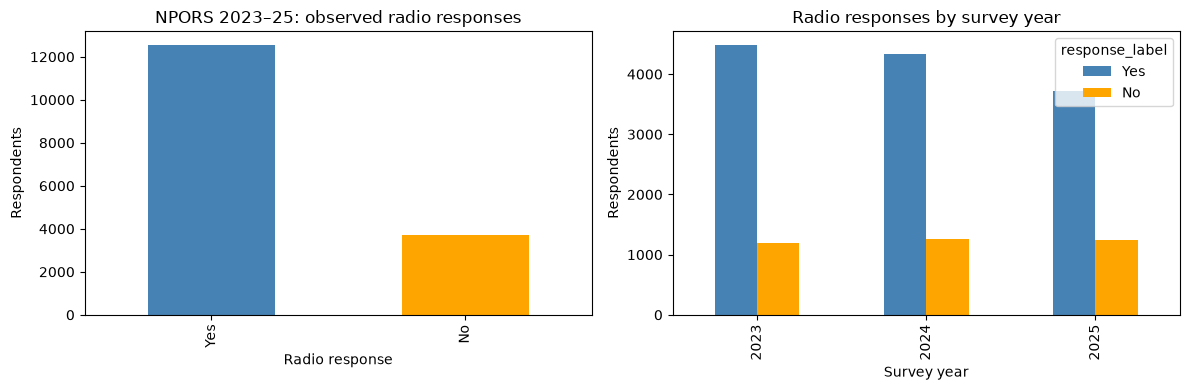

,survey_year,community,n,rate,percent
0,2023,Rural,1435,0.825784,82.578397
1,2023,Suburban,2703,0.792083,79.208287
2,2023,Urban,1472,0.745245,74.524457
3,2024,Rural,1245,0.824096,82.409639
4,2024,Suburban,2794,0.778454,77.845383
5,2024,Urban,1479,0.735632,73.563218
6,2025,Rural,1224,0.796569,79.656863
7,2025,Suburban,2316,0.750000,75.000000
8,2025,Urban,1381,0.703838,70.383780


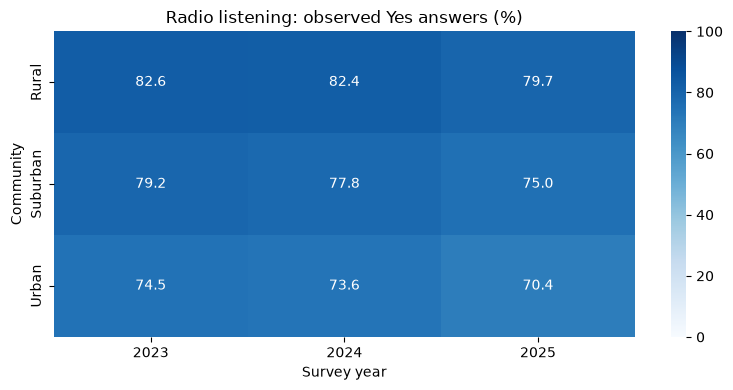

In [11]:
radio_long=enriched.loc[enriched['question_code'].eq('RADIO')].copy()
radio_counts=(radio_long.groupby(['survey_year','response_label'],dropna=False).size().rename('n').reset_index())
display(radio_counts)
observed_radio=radio_long.loc[radio_long['response_status'].eq('Observed')].copy()
radio_table=pd.crosstab(observed_radio['survey_year'],observed_radio['response_label']).reindex(columns=['Yes','No'],fill_value=0)
fig,axes=plt.subplots(1,2,figsize=(12,4))
observed_radio['response_label'].value_counts().reindex(['Yes','No']).plot.bar(ax=axes[0],color=['steelblue','orange'])
axes[0].set(title='NPORS 2023–25: observed radio responses',xlabel='Radio response',ylabel='Respondents')
radio_table.plot.bar(ax=axes[1],color=['steelblue','orange'])
axes[1].set(title='Radio responses by survey year',xlabel='Survey year',ylabel='Respondents')
plt.tight_layout(); plt.show()
radio_rate=observed_radio.assign(radio_yes=lambda x:x['response_label'].eq('Yes')).groupby(['survey_year','community'])['radio_yes'].agg(n='size',rate='mean').reset_index()
display(radio_rate.assign(percent=100*radio_rate['rate']))
heat=radio_rate.pivot(index='community',columns='survey_year',values='rate')*100
fig,ax=plt.subplots(figsize=(8,4))
sns.heatmap(heat,annot=True,fmt='.1f',cmap='Blues',vmin=0,vmax=100,ax=ax)
ax.set(title='Radio listening: observed Yes answers (%)',xlabel='Survey year',ylabel='Community')
plt.tight_layout(); plt.show()


**Observations and Reflection**


- The overall bar chart showed that more respondents answered Yes than No to radio listening.

- The grouped bar chart showed fewer Yes responses in later years. However, survey sample sizes also differed, so counts alone cannot establish a decline in listening rates.

- The heatmap showed the highest radio-listening percentages among rural respondents and the lowest among urban respondents. Percentages were lower in 2025 than in 2023 across all three community types—for example, rural respondents decreased from 82.6% to 79.7%.


- Counts show the number of respondents giving an answer. Proportions show that number relative to the group’s valid responses. Proportions make comparisons easier when group sizes differ. These charts show unweighted sample results, not population estimates.



- Missing answers are neither Yes nor No. Excluding them means the percentage is calculated among respondents who answered the question. For example, the 2023 denominator decreased from 5,733 to 5,687 after excluding 46 missing radio responses. Community comparisons also exclude respondents whose community type is missing.





#### **Age Distributions Before and After Imputation**

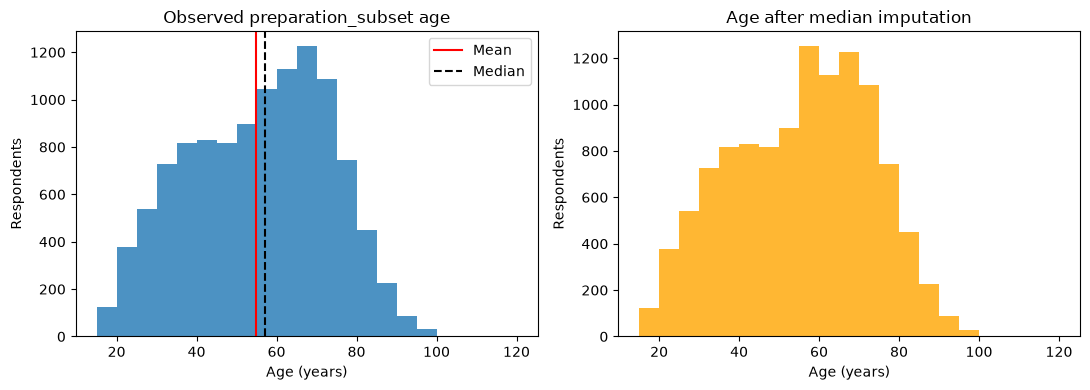

In [12]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].hist(age_original.dropna(), bins=np.arange(15,121,5), alpha=.8)
axes[0].axvline(age_original.mean(), color='red', label='Mean')
axes[0].axvline(age_original.median(), color='black', linestyle='--', label='Median')
axes[0].legend(); axes[0].set(title='Observed preparation_subset age',xlabel='Age (years)',ylabel='Respondents')
axes[1].hist(age_imputed, bins=np.arange(15,121,5), color='orange', alpha=.8)
axes[1].set(title='Age after median imputation',xlabel='Age (years)',ylabel='Respondents')
plt.tight_layout(); plt.show()


**Reflection**

The observed ages vary widely, with an average (mean) of approximately 54.93 years and a middle value (median) of 57 years. The mean being slightly below the median suggests some asymmetry toward younger ages.

Median imputation replaces all 206 missing ages with 57. This keeps every respondent in the demonstration dataset, but adds an artificial spike around age 57 because the same replacement is repeated—not because those respondents actually reported that age.

Imputation also reduces variance: the replacement ages are near the centre rather than spread across the age range. For example, the standard deviation decreases slightly from 17.68 to 17.52 years after median filling.

Therefore, filling missing ages preserves records but can make the distribution appear less variable than the unknown true ages might be.

#### **Category Distributions and Relationships**

,age,age_group,education,income_group,community
count,11153.000000,16119,16220,15595,16165
unique,NaN,4,3,6,3
top,NaN,65+,College graduate+,100k+,Suburban
freq,NaN,5665,7221,5118,7856
mean,54.933829,NaN,NaN,NaN,NaN
std,17.677886,NaN,NaN,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN
25%,40.000000,NaN,NaN,NaN,NaN
50%,57.000000,NaN,NaN,NaN,NaN
75%,69.000000,NaN,NaN,NaN,NaN


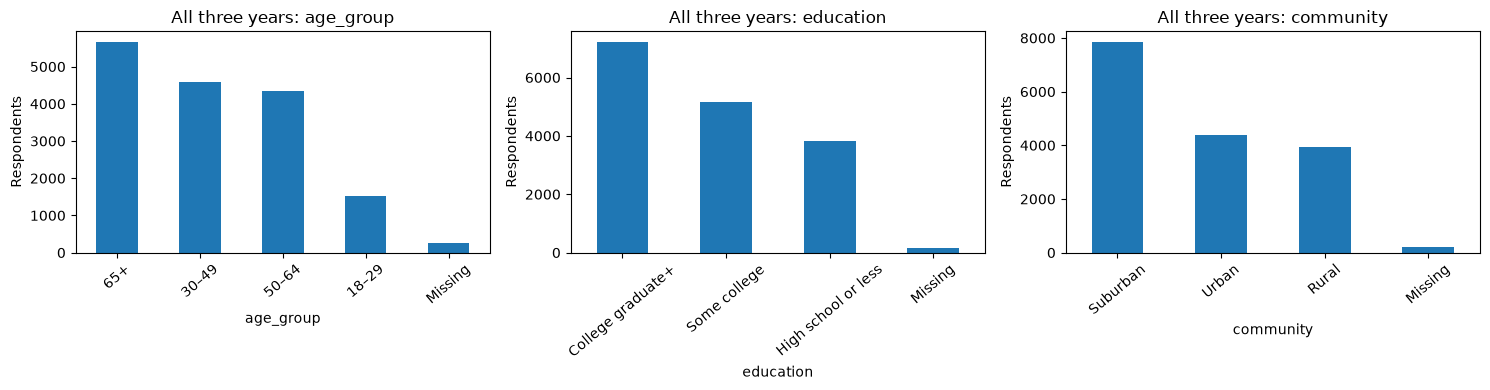

,n
almost_constant,
Other frequency,9489
Almost constantly,6111


,n,rate,percent
age_group,,,
18–29,1500,0.667333,66.733333
30–49,4543,0.581774,58.177416
50–64,4232,0.369329,36.932892
65+,5093,0.165914,16.591400
NaN,232,0.254310,25.431034


,n,rate,percent
education,,,
College graduate+,7139,0.456787,45.678666
High school or less,3326,0.311185,31.118461
Some college,5017,0.355790,35.579031
NaN,118,0.254237,25.423729


,n,rate,percent
income_group,,,
100k+,5077,0.480008,48.000788
30–40k,1388,0.331412,33.141210
40–50k,1272,0.355346,35.534591
50–70k,2140,0.349533,34.953271
70–100k,2421,0.383313,38.331268
<30k,2588,0.341190,34.119011
NaN,714,0.284314,28.431373


,n,rate,percent
community,,,
Rural,3666,0.310147,31.014730
Suburban,7604,0.396502,39.650184
Urban,4140,0.458454,45.845411
NaN,190,0.321053,32.105263


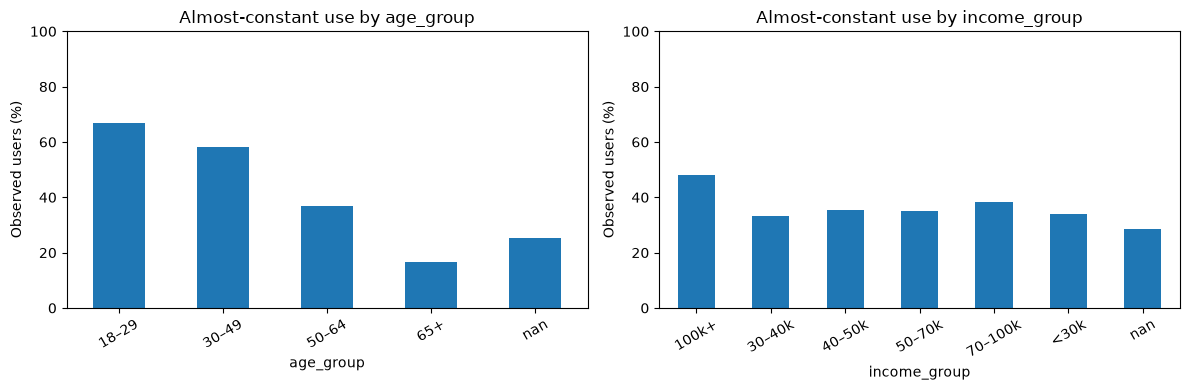

In [13]:
user_dev = combined.loc[combined['is_internet_user']].copy()
display(combined[features].describe(include='all'))
fig, axes=plt.subplots(1,3,figsize=(15,4))
for ax,col in zip(axes,['age_group','education','community']):
    combined[col].fillna('Missing').value_counts().plot.bar(ax=ax)
    ax.set(title=f'All three years: {col}',xlabel=col,ylabel='Respondents')
    ax.tick_params(axis='x',rotation=40)
plt.tight_layout(); plt.show()
display(user_dev['almost_constant'].value_counts().rename(index={0.:'Other frequency',1.:'Almost constantly'}).to_frame('n'))
group_rates={}
for col in ['age_group','education','income_group','community']:
    table=user_dev.groupby(col,dropna=False)['almost_constant'].agg(n='size',rate='mean')
    group_rates[col]=table
    display(table.assign(percent=100*table['rate']))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,col in zip(axes,['age_group','income_group']):
    table=group_rates[col]
    (100*table['rate']).plot.bar(ax=ax)
    ax.set(title=f'Almost-constant use by {col}',xlabel=col,ylabel='Observed users (%)',ylim=(0,100))
    ax.tick_params(axis='x',rotation=30)
plt.tight_layout(); plt.show()


#### **Visual Outlier Investigation**

Box plots use conventional IQR whiskers. The scatter plot displays ordinal frequency with slight jitter; its category codes are not continuous hours of internet use.

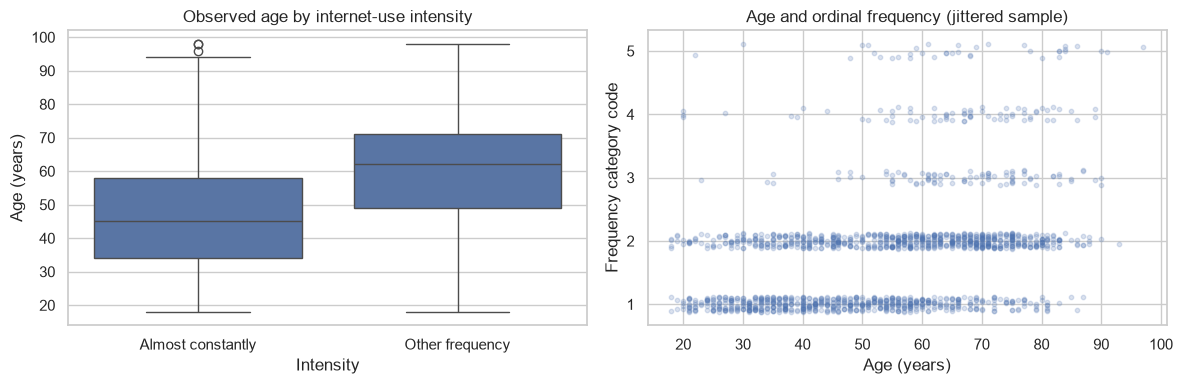

In [14]:
SEED = 42
ALPHA = 0.05
sns.set_theme(style='whitegrid')

observed=user_dev.dropna(subset=['age']).copy()
observed['intensity_label']=observed['almost_constant'].map({0.:'Other frequency',1.:'Almost constantly'})
fig,axes=plt.subplots(1,2,figsize=(12,4))
sns.boxplot(data=observed,x='intensity_label',y='age',ax=axes[0])
axes[0].set(title='Observed age by internet-use intensity',xlabel='Intensity',ylabel='Age (years)')
sample=observed.sample(n=min(1500,len(observed)),random_state=SEED)
jitter=np.random.default_rng(SEED).uniform(-.12,.12,len(sample))
axes[1].scatter(sample['age'],sample['frequency_code']+jitter,alpha=.2,s=10)
axes[1].set(title='Age and ordinal frequency (jittered sample)',xlabel='Age (years)',ylabel='Frequency category code',yticks=list(range(1,6)))
plt.tight_layout(); plt.show()



### **Task 1.5 – Inferential Statistics**

All tests are grouped here. Using 2024 only to avoid treating year changes as within-person changes and to keep numeric-age measurement consistent. Using one row per respondent, with observed responses. Imputed ages and melted duplicates are not entering these tests.




#### **The Question**

**Does Mean Age Differ by Internet-Use Intensity?**

H0: μ_almost-constant = μ_other-frequency. 

H1: the means differ.


μ (mu) means the population’s average age. The text after it identifies the group.
- μ_almost-constant: average age of internet users who report using it almost constantly.
- μ_other-frequency: average age of internet users who report using it at any of the other frequencies: several times daily, once daily, several times weekly, or less often.
“Other frequency” excludes nonusers and missing/refused answers.
The hypotheses mean:
- H0 (null hypothesis): The two groups have the same average age.
- H1 (alternative hypothesis): The two groups have different average ages.


Age measurement limitation: the released value 98 means 98 or older. It is retained as a lower-bound value and flagged, so age summaries and test results are approximate. The 2025 file has only age groups and cannot supply exact ages for this test.

In [15]:
display(pd.crosstab(combined['survey_year'],combined['age_status']))


age_status,Not released in 2025,Observed release age,Refused,Top-coded 98+
survey_year,,,,
2023,0,5631,93,9
2024,0,5508,113,5
2025,5022,0,0,0


,count,mean,median,std
almost_constant,,,,
0.0,3172,60.233922,63.0,16.211512
1.0,2109,45.568042,44.0,15.426257


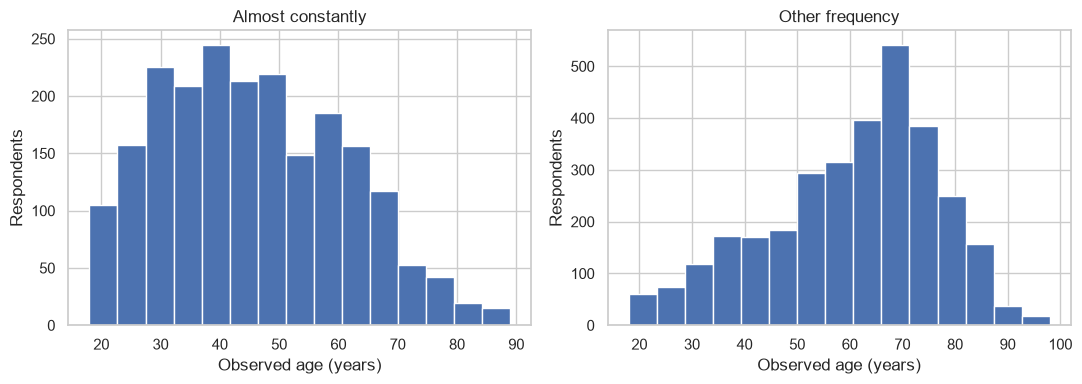

In [16]:
test_data=combined.loc[combined['survey_year'].eq(2024)&combined['is_internet_user']].copy()
numeric_test=test_data.dropna(subset=['age'])
a=numeric_test.loc[numeric_test['almost_constant'].eq(1),'age']
b=numeric_test.loc[numeric_test['almost_constant'].eq(0),'age']
assert min(len(a),len(b))>1
display(numeric_test.groupby('almost_constant')['age'].agg(['count','mean','median','std']))
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,x,label in zip(axes,[a,b],['Almost constantly','Other frequency']):
    ax.hist(x,bins=15); ax.set(title=label,xlabel='Observed age (years)',ylabel='Respondents')
plt.tight_layout(); plt.show()


#### **Mandatory Normality Checks: Q–Q Plots and Shapiro–Wilk**


Completing these checks for each group before executing the t-test cell. 
In a Q–Q plot, approximately straight points support an approximately normal shape; examine skew, tails and unusual observations. 
For Shapiro–Wilk, H0 is that the sampled values follow a normal distribution; p<0.05 provides evidence against exact normality. p≥0.05 does not prove normality.

Running Shapiro on all available observations up to 5,000 per group. If a group is larger, use a fixed-seed random sample of 5,000 and report both sizes, because SciPy warns that larger-sample p-values may be inaccurate. Q–Q plots use the full observed group.



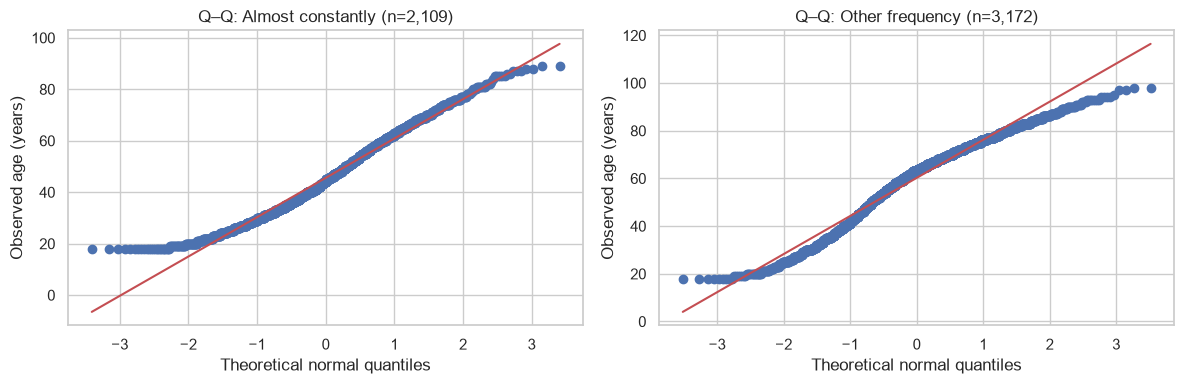

,group,full_n,shapiro_n,W,p_value,normality_decision
0,Almost constantly,2109,2109,0.978723,3.392817e-17,Evidence against exact normality
1,Other frequency,3172,3172,0.969569,2.043717e-25,Evidence against exact normality


In [17]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
normality_rows=[]
for offset,(ax,label,values) in enumerate(zip(axes,['Almost constantly','Other frequency'],[a,b])):
    x=np.asarray(values,dtype=float)
    assert len(x)>=3 and np.isfinite(x).all()
    stats.probplot(x,dist='norm',plot=ax)
    ax.set(title=f'Q–Q: {label} (n={len(x):,})',xlabel='Theoretical normal quantiles',ylabel='Observed age (years)')
    checked=np.random.default_rng(SEED+offset).choice(x,size=5000,replace=False) if len(x)>5000 else x
    shapiro=stats.shapiro(checked)
    normality_rows.append({'group':label,'full_n':len(x),'shapiro_n':len(checked),
        'W':shapiro.statistic,'p_value':shapiro.pvalue,
        'normality_decision':'Evidence against exact normality' if shapiro.pvalue<ALPHA else 'Insufficient evidence against normality'})
plt.tight_layout(); plt.show()
normality_report=pd.DataFrame(normality_rows)
display(normality_report)
normality_report.to_csv(RESULTS_DIR/'rq1_normality_checks.csv',index=False)
normality_checks_completed=True




#### Pre-Test Justification

The Q–Q plots show that ages follow the reference line reasonably closely in the centre, but depart from it in the tails. The departures are more noticeable in the **other-frequency** group, suggesting that neither group’s age distribution is exactly normal.

Shapiro–Wilk tests support this observation:

| Group | Sample size | W | p-value |
|---|---:|---:|---:|
| Almost-constant users | 2,109 | 0.9787 | 3.39 × 10⁻¹⁷ |
| Other-frequency users | 3,172 | 0.9696 | 2.04 × 10⁻²⁵ |

Both p-values are below **α = 0.05**, providing evidence against normality. However, Shapiro–Wilk is sensitive to departures from normality in large samples.

We will proceed with **Welch’s two-sample t-test** because both groups are large and observed ages are bounded. Large group sizes can make inference about means reasonably robust to non-normality. Welch’s test also allows unequal variances, although it does not correct non-normality itself.

The results must remain qualified: observations are treated as independent, missing ages are excluded, some ages are top-coded as 98+, and the calculation does not account for Pew’s complex survey design. 

In [18]:
assert normality_checks_completed, 'Run the mandatory Q–Q and Shapiro checks first.'
t_result=stats.ttest_ind(a,b,equal_var=False)
print(f'Welch t={t_result.statistic:.4f}, p={t_result.pvalue:.6g}, difference={a.mean()-b.mean():.2f} years')
print('Reject H0' if t_result.pvalue<ALPHA else 'Do not reject H0')


Welch t=-33.1531, p=1.26141e-216, difference=-14.67 years
Reject H0


###  Question Reflection

Among the analyzed 2024 respondents, almost-constant internet users had a mean age of **45.57 years**, compared with **60.23 years** for other-frequency users. Almost-constant users were therefore approximately **14.67 years younger on average**.

The Q–Q plots showed departures from normality, particularly in the tails, and both Shapiro–Wilk tests returned p-values below 0.05. Nevertheless, we proceeded with Welch’s t-test as a classroom approximation because both groups were large. Shapiro rejection alone does not automatically invalidate a t-test, and Welch’s method allows unequal variances.

The test produced **t ≈ −33.15** and **p ≈ 1.26 × 10⁻²¹⁶**. Under the test’s assumptions, we reject the null hypothesis of equal population mean ages. The estimated difference of 14.67 years describes the magnitude of the observed association; it does not establish that age causes internet-use intensity.

These findings require caution. The analysis excludes nonusers, unknown/refused frequency answers and missing ages, so respondents with observed answers may differ from those excluded. Ages recorded as 98+ also make age summaries approximate. Finally, the unweighted test does not account for Pew’s complex survey design. Large sample sizes do not correct that limitation, so the result should not be presented as design-corrected inference about all U.S. adults.

In [19]:
statistics_report = pd.DataFrame([{
    'question': 'RQ1',
    'test': 'Welch age vs intensity',
    'n_almost_constant': len(a),
    'n_other_frequency': len(b),
    'mean_almost_constant': a.mean(),
    'mean_other_frequency': b.mean(),
    'statistic': t_result.statistic,
    'p_value': t_result.pvalue,
    'effect': a.mean() - b.mean(),
    'effect_units': 'age years'
}])
statistics_report.to_csv(RESULTS_DIR / 'statistical_tests.csv', index=False)
display(statistics_report)


,question,test,n_almost_constant,n_other_frequency,mean_almost_constant,mean_other_frequency,statistic,p_value,effect,effect_units
0,RQ1,Welch age vs intensity,2109,3172,45.568042,60.233922,-33.153138,1.261411e-216,-14.66588,age years


---
# **Answer to the Research Question**

**The question that was asked was whether mean age differs between almost-constant internet users and users at other frequencies.** 


Among the analyzed 2024 respondents, the 2,109 almost-constant users had a mean age of 45.57 years, while the 3,172 other-frequency users had a mean age of 60.23 years. Almost-constant users were therefore approximately 14.67 years younger on average.

The age-distribution plots supported this difference. However, the Q–Q plots showed departures from normality, particularly in the tails, and both Shapiro–Wilk tests produced p-values below 0.05. These results indicate non-normal distributions but do not automatically invalidate every t-test. We used Welch’s t-test because both groups were large; Welch’s method also allows unequal variances.

The test returned t = −33.15, p < 0.001. Under its assumptions, we reject the null hypothesis of equal population mean ages. The age difference suggests a substantial association between age and internet-use intensity, without establishing causation.

We also take into account that preparation decisions matter when interpreting this result. Missing ages were excluded rather than imputed, preserving the distinction between observed and estimated values. Nevertheless, respondents with observed answers may differ from those excluded. Ages recorded as 98+ also make the means approximate. 

 Finally, the unweighted test does not account for Pew’s complex survey design. Large sample sizes do not resolve that limitation, so these findings should not be presented as design-corrected inference about all U.S. adults.